# 🎓 Análisis Exploratorio: ¿Dónde estudian los niños de Barcelona? (cursos 2020/21 – 2024/25)

## Objetivo
**¿Dónde estudian los niños de Barcelona —en la escuela pública, concertada o privada— y depende del distrito en el que viven?**

### Preguntas
1. ¿Qué proporción de alumnos estudia en cada tipo de centro y cómo varía entre distritos?
2. ¿Influye el nivel de renta del distrito en el tipo de escuela?
3. ¿Hay diferencias en el número de alumnos por grupo entre la pública, la concertada y la privada?
4. ¿Cómo ha evolucionado la matrícula en P3? ¿Se nota la caída de la natalidad?
5. ¿Quiénes son los titulares de los centros concertados (órdenes religiosas, fundaciones, cooperativas...)?
6. ¿Hay diferencias en el equilibrio entre chicas y chicos según el tipo de centro?

**Fuente:** Generalitat de Catalunya – *Alumnes matriculats per ensenyament i unitats dels centres docents* (API Socrata)

## 🛠️ Paso 0: Configuración inicial

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"

## 📥 Paso 1: Cargar los datos desde la API
Pedimos a la API solo los registros de Barcelona y de los últimos 5 cursos completos.

In [2]:
URL = "https://analisi.transparenciacatalunya.cat/resource/xvme-26kg.json"
CURSOS = ["2020/2021", "2021/2022", "2022/2023", "2023/2024", "2024/2025"]
LIMITE = 10000

lista_cursos = ",".join(f"'{c}'" for c in CURSOS)
filtro = f"nom_municipi='Barcelona' AND curs IN ({lista_cursos})"

paginas = []
offset = 0
while True:
    params = {
        "$where": filtro,
        "$limit": LIMITE,
        "$offset": offset,
        "$order": ":id",
    }
    respuesta = requests.get(URL, params=params)
    respuesta.raise_for_status()
    datos = respuesta.json()
    if not datos:
        break
    paginas.extend(datos)
    print(f"Descargadas {len(paginas)} filas...")
    offset += LIMITE

df = pd.DataFrame(paginas)
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")

Descargadas 10000 filas...
Descargadas 20000 filas...
Descargadas 30000 filas...
Descargadas 40000 filas...
Descargadas 42611 filas...
Filas: 42611, Columnas: 35


### Guardar una copia local
Guardamos los datos en `data/raw/` para no tener que pedirlos a la API cada vez que ejecutemos el notebook.

In [3]:
df.to_csv("../data/raw/matriculas_bcn_raw.csv", index=False)
print("Guardado en data/raw/")

Guardado en data/raw/


## 👀 Paso 2: Primera exploración

### 2.1 Primeras filas

In [4]:
df.head()

,curs,any,codi_centre,denominaci_completa,codi_naturalesa,nom_naturalesa,codi_titularitat,nom_titularitat,codi_delegaci,nom_delegaci,...,nivell,modalitat,per_ode_matr_cula,matr_cules_total,matr_cules_dones,matr_cules_homes,unitats,matr_cula_concertada,tem_tica,grau
0,2022/2023,2022,08001595,Escola Baixeras,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,1,PRESENCIAL,ANUAL,16,4,12,1,NaN,NaN,NaN
1,2022/2023,2022,08001595,Escola Baixeras,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,2,PRESENCIAL,ANUAL,18,7,11,1,NaN,NaN,NaN
2,2022/2023,2022,08001595,Escola Baixeras,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,3,PRESENCIAL,ANUAL,18,7,11,1,NaN,NaN,NaN
3,2022/2023,2022,08001595,Escola Baixeras,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,1,PRESENCIAL,ANUAL,20,12,8,1,NaN,NaN,NaN
4,2022/2023,2022,08001595,Escola Baixeras,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,2,PRESENCIAL,ANUAL,21,10,11,1,NaN,NaN,NaN


### 2.2 Dimensiones del dataset

In [5]:
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")

Filas: 42611, Columnas: 35


### 2.3 Información general: columnas, tipos y valores no nulos

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 42611 entries, 0 to 42610
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   curs                      42611 non-null  str  
 1   any                       42611 non-null  str  
 2   codi_centre               42611 non-null  str  
 3   denominaci_completa       42611 non-null  str  
 4   codi_naturalesa           42611 non-null  str  
 5   nom_naturalesa            42611 non-null  str  
 6   codi_titularitat          42611 non-null  str  
 7   nom_titularitat           42611 non-null  str  
 8   codi_delegaci             42611 non-null  str  
 9   nom_delegaci              42611 non-null  str  
 10  codi_comarca              42611 non-null  str  
 11  nom_comarca               42611 non-null  str  
 12  codi_municipi_5           42611 non-null  str  
 13  codi_municip_6            42611 non-null  str  
 14  nom_municipi              42611 non-null  str  
 

### 2.4 Valores faltantes por columna

In [7]:
faltantes = df.isnull().sum()
porcentaje = (faltantes / len(df) * 100).round(1)
pd.DataFrame({"faltantes": faltantes, "%": porcentaje})[faltantes > 0].sort_values("%", ascending=False)

,faltantes,%
tem_tica,34952,82.0
grau,29592,69.4
matr_cula_concertada,22486,52.8
nivell,1536,3.6
codi_ensenyament,481,1.1
nom_ensenyament,482,1.1
coordenades_utm_x,30,0.1
coordenades_utm_y,30,0.1
coordenades_geo_x,30,0.1
coordenades_geo_y,30,0.1


### 2.5 Filas duplicadas

In [8]:
print(f"Filas duplicadas: {df.duplicated().sum()}")

Filas duplicadas: 26


In [9]:
df[df.duplicated(keep=False)].sort_values(["codi_centre", "curs"]).head(10)

,curs,any,codi_centre,denominaci_completa,codi_naturalesa,nom_naturalesa,codi_titularitat,nom_titularitat,codi_delegaci,nom_delegaci,...,nivell,modalitat,per_ode_matr_cula,matr_cules_total,matr_cules_dones,matr_cules_homes,unitats,matr_cula_concertada,tem_tica,grau
10062,2020/2021,2020,08038570,EOI de Barcelona,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,1,PRESENCIAL,2n QUADRIMESTRE,26,18,8,0,NaN,NaN,IDILNA
10105,2020/2021,2020,08038570,EOI de Barcelona,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,1,PRESENCIAL,2n QUADRIMESTRE,29,19,10,0,NaN,NaN,IDILNB
10125,2020/2021,2020,08038570,EOI de Barcelona,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,1,PRESENCIAL,2n QUADRIMESTRE,24,15,9,0,NaN,NaN,IDILNB
10128,2020/2021,2020,08038570,EOI de Barcelona,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,2,PRESENCIAL,2n QUADRIMESTRE,20,14,6,0,NaN,NaN,IDILNB
10146,2020/2021,2020,08038570,EOI de Barcelona,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,1,PRESENCIAL,2n QUADRIMESTRE,8,3,5,0,NaN,NaN,IDILNI
10162,2020/2021,2020,08038570,EOI de Barcelona,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,1,PRESENCIAL,2n QUADRIMESTRE,14,10,4,0,NaN,NaN,IDILNI
10180,2020/2021,2020,08038570,EOI de Barcelona,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,1,PRESENCIAL,2n QUADRIMESTRE,26,18,8,0,NaN,NaN,IDILNA
10196,2020/2021,2020,08038570,EOI de Barcelona,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,1,PRESENCIAL,2n QUADRIMESTRE,29,19,10,0,NaN,NaN,IDILNB
10200,2020/2021,2020,08038570,EOI de Barcelona,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,1,PRESENCIAL,2n QUADRIMESTRE,24,15,9,0,NaN,NaN,IDILNB
10201,2020/2021,2020,08038570,EOI de Barcelona,1,Públic,01,Departament d'Ensenyament,0108,Consorci d'Educació de Barcelo,...,2,PRESENCIAL,2n QUADRIMESTRE,20,14,6,0,NaN,NaN,IDILNB


### 2.6 Valores únicos de los distritos

In [10]:
df["nom_dm"].value_counts()

nom_dm
Eixample                     6824
Sarrià - Sant Gervasi        5715
Sant Martí                   4938
Ciutat vella                 4622
Horta - Guinardó             4229
Nou Barris                   4188
Sants - Montjuïc             3961
Sant Andreu                  3145
Gràcia                       2610
Les Corts                    2314
DM VIII - Nou Barris           19
DM VII - Horta - Guinardó      19
DM II - Eixample                6
DM III - Sants - Montjuïc       6
DM IX - Sant Andreu             6
DM X - Sant Martí               5
DM I - Ciutat vella             4
Name: count, dtype: int64

### 2.7 ¿Los valores faltantes de `matr_cula_concertada` son de centros públicos?

In [11]:
pd.crosstab(df["nom_naturalesa"], df["matr_cula_concertada"].fillna("FALTANTE"))

matr_cula_concertada,FALTANTE,NO,SI
nom_naturalesa,,,
Privat,4096,6099,13046
Públic,18390,980,0


### 📝 Observaciones de la primera exploración
- **Tipos de datos:** todas las columnas llegan como texto (`str`), incluso las numéricas (`matr_cules_total`, `unitats`). Hay que convertirlas.
- **Distritos inconsistentes:** `nom_dm` tiene valores como "DM VIII - Nou Barris" además de "Nou Barris" (17 valores para 10 distritos). Además, "Ciutat vella" debería ser "Ciutat Vella" (importante para el merge con los datos de renta).
- **Concertada:** el 52% de `matr_cula_concertada` está vacío, pero el 82% de esos vacíos (18.390) son centros públicos, donde la pregunta no aplica (*faltante estructural*). El problema real son **4.096 registros privados** sin saber si son concertados o privados. Además, en centros públicos el mismo significado aparece como vacío o como "NO".
- **Duplicados:** 26 filas duplicadas, todas de dos Escoles Oficials d'Idiomes (enseñanza de adultos).
- **Coordenadas:** 30 filas sin coordenadas.
- **Columnas casi vacías:** `tem_tica` y `grau` solo están rellenas en algunos tipos de estudios.

### 🎯 Decisión de alcance
Nuestra pregunta es sobre **los niños**, así que nos quedamos con las etapas de 3 a 16 años:
- **Educació Infantil – segon cicle (P3-P5):** casi universal y se imparte en las escuelas. El primer ciclo (0-3) es voluntario y funciona como un sistema aparte (escoles bressol).
- **Educació Primària y ESO:** etapas obligatorias, todas las familias tienen que elegir centro.

Excluimos Batxillerat y FP (no obligatorios; el concierto suele cubrir solo las etapas obligatorias, lo que distorsionaría la comparación) y la enseñanza de adultos, idiomas y artísticas (fuera de la pregunta). Con este filtro, los 26 duplicados también quedan fuera.

## 🧹 Paso 3: Limpieza de datos

### 3.1 Filtrar las etapas de 3 a 16 años
Aplicamos la decisión de alcance. Usamos `codi_ensenyament` (código) en lugar de `nom_estudis` (texto), porque los códigos son estables y no dependen de acentos ni mayúsculas.

In [12]:
ETAPAS = {
    "EINFLOE 2C": "Infantil (P3-P5)",
    "EPRILOE": "Primaria",
    "ESO LOE": "ESO",
}

filas_antes = len(df)
df_limpio = df[df["codi_ensenyament"].isin(ETAPAS.keys())].copy()
df_limpio["etapa"] = df_limpio["codi_ensenyament"].map(ETAPAS)

print(f"Filas antes: {filas_antes}, después: {len(df_limpio)} ({len(df_limpio) / filas_antes:.0%})")
df_limpio["etapa"].value_counts()

Filas antes: 42611, después: 19289 (45%)


etapa
Primaria            9910
Infantil (P3-P5)    5067
ESO                 4312
Name: count, dtype: int64

### 3.2 Comprobar duplicados tras el filtro

In [13]:
print(f"Filas duplicadas: {df_limpio.duplicated().sum()}")

Filas duplicadas: 0


### 3.3 Seleccionar y renombrar columnas
Nos quedamos solo con las columnas que necesitamos para responder a nuestras preguntas y les damos nombres en español, más fáciles de entender.

**Eliminamos:**
- Columnas con el mismo valor en todas las filas (municipio, comarca, delegación, período de matrícula): como solo analizamos Barcelona, no aportan información.
- Columnas redundantes: códigos que tienen su nombre en otra columna (`codi_naturalesa`), `any` (mismo dato que `curs`) y coordenadas UTM (tenemos latitud/longitud).
- Columnas de tipo de estudios: las sustituye la nueva columna `etapa`.
- `tem_tica` y `grau`: 100% vacías en nuestras etapas.
- `codi_districte_municipal`: mezcla códigos y nombres; usamos `nom_dm`.

In [14]:
COLUMNAS = {
    "curs": "curso",
    "codi_centre": "codigo_centro",
    "denominaci_completa": "nombre_centro",
    "nom_naturalesa": "naturaleza",
    "matr_cula_concertada": "concertada",
    "nom_titularitat": "titularidad",
    "nom_dm": "distrito",
    "coordenades_geo_y": "latitud",
    "coordenades_geo_x": "longitud",
    "nivell": "nivel",
    "modalitat": "modalidad",
    "matr_cules_total": "alumnos_total",
    "matr_cules_dones": "chicas",
    "matr_cules_homes": "chicos",
    "unitats": "grupos",
}

df_limpio = df_limpio[list(COLUMNAS.keys()) + ["etapa"]].rename(columns=COLUMNAS)
print(f"Columnas: {df_limpio.shape[1]}")
df_limpio.head()

Columnas: 16


,curso,codigo_centro,nombre_centro,naturaleza,concertada,titularidad,distrito,latitud,longitud,nivel,modalidad,alumnos_total,chicas,chicos,grupos,etapa
0,2022/2023,08001595,Escola Baixeras,Públic,NaN,Departament d'Ensenyament,Ciutat vella,41.382837911,2.179781021,1,PRESENCIAL,16,4,12,1,Infantil (P3-P5)
1,2022/2023,08001595,Escola Baixeras,Públic,NaN,Departament d'Ensenyament,Ciutat vella,41.382837911,2.179781021,2,PRESENCIAL,18,7,11,1,Infantil (P3-P5)
2,2022/2023,08001595,Escola Baixeras,Públic,NaN,Departament d'Ensenyament,Ciutat vella,41.382837911,2.179781021,3,PRESENCIAL,18,7,11,1,Infantil (P3-P5)
3,2022/2023,08001595,Escola Baixeras,Públic,NaN,Departament d'Ensenyament,Ciutat vella,41.382837911,2.179781021,1,PRESENCIAL,20,12,8,1,Primaria
4,2022/2023,08001595,Escola Baixeras,Públic,NaN,Departament d'Ensenyament,Ciutat vella,41.382837911,2.179781021,2,PRESENCIAL,21,10,11,1,Primaria


### 3.4 Corregir los tipos de datos
La API devuelve todo como texto. Convertimos a número las columnas numéricas.
- `pd.to_numeric(errors="coerce")`: si algún valor no se puede convertir, lo pone como `NaN` en lugar de dar error. Después comprobamos que no hayamos creado nulos nuevos.
- `Int64` (con mayúscula) es el entero de pandas que admite valores nulos; `nivel` tiene 107 vacíos.

In [15]:
COLUMNAS_ENTERAS = ["nivel", "alumnos_total", "chicas", "chicos", "grupos"]
COLUMNAS_DECIMALES = ["latitud", "longitud"]

nulos_antes = df_limpio[COLUMNAS_ENTERAS + COLUMNAS_DECIMALES].isnull().sum()

for col in COLUMNAS_ENTERAS:
    df_limpio[col] = pd.to_numeric(df_limpio[col], errors="coerce").astype("Int64")
for col in COLUMNAS_DECIMALES:
    df_limpio[col] = pd.to_numeric(df_limpio[col], errors="coerce")

nulos_despues = df_limpio[COLUMNAS_ENTERAS + COLUMNAS_DECIMALES].isnull().sum()
print("Nulos nuevos creados por la conversión:", (nulos_despues - nulos_antes).sum())
df_limpio.dtypes

Nulos nuevos creados por la conversión: 0


curso                str
codigo_centro        str
nombre_centro        str
naturaleza           str
concertada           str
titularidad          str
distrito             str
latitud          float64
longitud         float64
nivel              Int64
modalidad            str
alumnos_total      Int64
chicas             Int64
chicos             Int64
grupos             Int64
etapa                str
dtype: object

### 3.5 Estadística descriptiva de las columnas numéricas

In [16]:
df_limpio.describe()

,latitud,longitud,nivel,alumnos_total,chicas,chicos,grupos
count,19263.000000,19263.000000,19182.0,19289.0,19289.0,19289.0,19289.0
mean,41.412515,2.154271,2.875769,46.442947,22.758774,23.684172,1.832029
std,0.063696,0.122262,1.542829,37.159263,18.555144,19.458842,0.96694
min,40.539402,0.476270,1.0,1.0,0.0,0.0,0.0
25%,41.391370,2.143079,2.0,25.0,12.0,12.0,1.0
50%,41.407415,2.166792,3.0,43.0,20.0,21.0,2.0
75%,41.424457,2.182434,4.0,54.0,28.0,29.0,2.0
max,42.395185,3.082864,6.0,1037.0,518.0,531.0,7.0


### 3.6 Coordenadas imposibles
En la estadística descriptiva vimos que la latitud va de 40,54 a 42,40 y la longitud de 0,48 a 3,08. Barcelona está aproximadamente entre **41,3–41,5 de latitud** y **2,0–2,3 de longitud**, así que hay centros situados fuera de la ciudad (cerca de Tortosa o de la frontera con Francia), aunque su distrito es de Barcelona.

**❓ ¿Cuántas filas tienen coordenadas fuera de Barcelona y de qué cursos son?**

In [17]:
fuera_bcn = df_limpio[~df_limpio["latitud"].between(41.3, 41.5) | ~df_limpio["longitud"].between(2.0, 2.3)]
print(f"Filas con coordenadas fuera de Barcelona: {len(fuera_bcn)}")
fuera_bcn["curso"].value_counts()

Filas con coordenadas fuera de Barcelona: 460


curso
2021/2022    386
2022/2023     38
2023/2024     13
2024/2025     13
2020/2021     10
Name: count, dtype: int64

> **💡 ¿Qué aprendemos?** Hay 460 filas con coordenadas no válidas: 434 fuera de Barcelona y 26 sin coordenadas. **386 de ellas (84%) son del curso 2021/2022**, lo que indica un error en la publicación de ese año más que un problema de los centros.

> **✅ Decisión:** la ubicación de un centro no cambia de un año a otro. Por eso sustituimos las coordenadas incorrectas por la mediana de las coordenadas válidas del mismo centro (`codigo_centro`) en otros cursos.
> - **¿Por qué no eliminamos las filas?** Perderíamos alumnos reales de nuestro análisis. Solo la ubicación es incorrecta; el resto de los datos es válido.
> - **¿Por qué no buscamos por el nombre del centro?** Nombres como "Montserrat" o "Sant Pau" pueden corresponder a muchos lugares de Cataluña. Usar los datos del mismo centro en otros años es más fiable.

In [18]:
LAT_BCN = (41.3, 41.5)
LON_BCN = (2.0, 2.3)

def coordenadas_validas(df):
    return df["latitud"].between(*LAT_BCN) & df["longitud"].between(*LON_BCN)

validas = coordenadas_validas(df_limpio)
coords_por_centro = (
    df_limpio[validas]
    .groupby("codigo_centro")[["latitud", "longitud"]]
    .median()
)

df_limpio.loc[~validas, "latitud"] = df_limpio.loc[~validas, "codigo_centro"].map(coords_por_centro["latitud"])
df_limpio.loc[~validas, "longitud"] = df_limpio.loc[~validas, "codigo_centro"].map(coords_por_centro["longitud"])

print(f"Filas con coordenadas no válidas: antes {(~validas).sum()}, después {(~coordenadas_validas(df_limpio)).sum()}")

Filas con coordenadas no válidas: antes 460, después 59


> **📊 Resultado:** pasamos de 460 a 59 filas no válidas. El mismo método también rellenó las 26 filas que no tenían coordenadas (`between()` devuelve `False` para los valores nulos).
>
> Las 59 filas restantes son todas del *Institut Escola Coves d'en Cimany*, que no tiene ninguna coordenada válida en ningún curso.

> **✅ Decisión:** como es un único centro, buscamos su ubicación manualmente en Google Maps.

In [19]:
COVES_DEN_CIMANY = df_limpio["nombre_centro"] == "Institut Escola Coves d'en Cimany"
df_limpio.loc[COVES_DEN_CIMANY, ["latitud", "longitud"]] = [41.420676, 2.152548]

print(f"Filas con coordenadas no válidas: {(~coordenadas_validas(df_limpio)).sum()}")

Filas con coordenadas no válidas: 0


> **📊 Resultado:** 0 filas con coordenadas no válidas. Todos los centros tienen ahora una ubicación dentro de Barcelona, necesaria para el mapa del dashboard.

> 📋 *Para el informe de calidad de datos:* 434 coordenadas fuera de Barcelona (casi todas de 2021/22) y 26 vacías → corregidas con el mismo centro en otros cursos; 1 centro corregido manualmente.

### 3.7 Valores extremos de alumnos
En la estadística descriptiva, el máximo de `alumnos_total` es **1.037 alumnos** en un solo registro, mientras que la mediana es 43. Como cada fila representa un curso (nivel) de un centro, un valor así parece imposible.

**❓ ¿Qué centros tienen los valores más altos?**

In [20]:
df_limpio.sort_values("alumnos_total", ascending=False).head(8)

,curso,codigo_centro,nombre_centro,naturaleza,concertada,titularidad,distrito,latitud,longitud,nivel,modalidad,alumnos_total,chicas,chicos,grupos,etapa
23344,2022/2023,08040126,Lyceé Français de Barcelone,Privat,NO,Altres estats UE,Sarrià - Sant Gervasi,41.392699,2.118257,<NA>,ESTRANGERS,1037,511,526,0,ESO
18634,2021/2022,08040126,Lyceé Français de Barcelone,Privat,NO,Altres estats UE,Sarrià - Sant Gervasi,41.392699,2.118257,<NA>,ESTRANGERS,1032,501,531,0,ESO
18633,2021/2022,08040126,Lyceé Français de Barcelone,Privat,NO,Altres estats UE,Sarrià - Sant Gervasi,41.392699,2.118257,<NA>,ESTRANGERS,1030,518,512,0,Primaria
32083,2023/2024,08040126,Lyceé Français de Barcelone,Privat,NO,Altres estats UE,Sarrià - Sant Gervasi,41.392699,2.118257,<NA>,ESTRANGERS,1027,498,529,0,ESO
41199,2024/2025,08040126,Lyceé Français de Barcelone,Privat,NO,Altres estats UE,Sarrià - Sant Gervasi,41.392760,2.118357,<NA>,ESTRANGERS,1025,496,529,0,ESO
10337,2020/2021,08040126,Lyceé Français de Barcelone,Privat,NO,Altres estats UE,Sarrià - Sant Gervasi,41.392699,2.118257,<NA>,ESTRANGERS,1018,494,524,0,ESO
23343,2022/2023,08040126,Lyceé Français de Barcelone,Privat,NO,Altres estats UE,Sarrià - Sant Gervasi,41.392699,2.118257,<NA>,ESTRANGERS,1012,492,520,0,Primaria
10336,2020/2021,08040126,Lyceé Français de Barcelone,Privat,NO,Altres estats UE,Sarrià - Sant Gervasi,41.392699,2.118257,<NA>,ESTRANGERS,1001,514,487,0,Primaria


In [21]:
extranjeros = df_limpio[df_limpio["modalidad"] == "ESTRANGERS"]
print(f"Filas: {len(extranjeros)} | Alumnos: {extranjeros['alumnos_total'].sum()} ({extranjeros['alumnos_total'].sum() / df_limpio['alumnos_total'].sum():.1%} del total)")
extranjeros.groupby("nombre_centro")["alumnos_total"].sum().sort_values(ascending=False)

Filas: 107 | Alumnos: 29339 (3.3% del total)


nombre_centro
Lyceé Français de Barcelone                           11719
Oak House British School                               3082
Escuela Suiza                                          2919
Collège Ferdinand de Lesseps                           2915
The Benjamin Franklin International School             2875
St. George School the British School of Catalunya      2583
Istituto Italiano Statale c.sc.el.e.sec. I e II gr     2120
Scuola dell'Infanzia Italiana parif. M. Montessori      344
Barcelona Montessori School                             306
Kensington School                                       215
Barcelona High School                                   160
Learnlife                                                73
AESA Prep Academy of Barcelona                           28
Name: alumnos_total, dtype: Int64

> **💡 ¿Qué aprendemos?** Los valores extremos son de centros que siguen un **sistema educativo extranjero** (modalidad `ESTRANGERS`), como el Lycée Français. Estos centros no declaran los alumnos por nivel (`nivel` vacío) ni por grupo (`grupos` = 0): el número es el **total de la etapa**. No es un error, es otro nivel de detalle.

> **✅ Decisión:** mantenemos estas filas, pero las marcamos con una nueva columna `sistema_extranjero`.
> - **Las incluimos** en los recuentos de alumnos por tipo de centro y distrito: son alumnos reales de Barcelona y todos estudian en centros privados. Si los elimináramos, subestimaríamos el peso de la escuela privada.
> - **Las excluimos** de los análisis por nivel y de alumnos por grupo, porque no tienen esa información.

In [22]:
df_limpio["sistema_extranjero"] = df_limpio["modalidad"] == "ESTRANGERS"
df_limpio = df_limpio.drop(columns="modalidad")

df_limpio["sistema_extranjero"].value_counts()

sistema_extranjero
False    19182
True       107
Name: count, dtype: int64

> **📊 Resultado:** 107 filas marcadas como `sistema_extranjero = True`. Eliminamos la columna `modalidad`, porque la nueva columna booleana contiene la misma información de forma más clara.

### 3.8 Registros con 0 grupos
Hay filas con alumnos pero sin grupos (`grupos` = 0). Con ellas no podríamos calcular los alumnos por grupo (pregunta 3): dividir entre 0 no tiene sentido.

**❓ ¿De qué centros son y cómo se organizan?**

In [23]:
sin_grupos = df_limpio[(df_limpio["grupos"] == 0) & ~df_limpio["sistema_extranjero"]]
print(f"Filas con 0 grupos (sin contar sistema extranjero): {len(sin_grupos)}")
print(sin_grupos["naturaleza"].value_counts())

# Ejemplo: un centro con 0 grupos en un nivel
ejemplo = sin_grupos.iloc[0]
df_limpio[
    (df_limpio["codigo_centro"] == ejemplo["codigo_centro"])
    & (df_limpio["curso"] == ejemplo["curso"])
    & (df_limpio["etapa"] == ejemplo["etapa"])
][["nombre_centro", "curso", "etapa", "nivel", "alumnos_total", "grupos"]]

Filas con 0 grupos (sin contar sistema extranjero): 348
naturaleza
Privat    335
Públic     13
Name: count, dtype: int64


,nombre_centro,curso,etapa,nivel,alumnos_total,grupos
36,Escola Can Clos,2022/2023,Infantil (P3-P5),1,10,1
37,Escola Can Clos,2022/2023,Infantil (P3-P5),2,11,0
38,Escola Can Clos,2022/2023,Infantil (P3-P5),3,5,1


> **💡 ¿Qué aprendemos?** Muchos de estos centros son pequeños y trabajan con **grupos mixtos** (por ejemplo, P3 y P4 en la misma clase). El grupo se registra en un solo nivel y los demás niveles aparecen con 0 grupos. No es un error: es la forma de organizar la escuela.

**❓ ¿Cuántos centros no tienen ningún grupo registrado en toda la etapa?**

In [24]:
por_etapa = (
    df_limpio[~df_limpio["sistema_extranjero"]]
    .groupby(["curso", "codigo_centro", "etapa"])[["alumnos_total", "grupos"]]
    .sum()
)
sin_grupos_etapa = por_etapa[por_etapa["grupos"] == 0]
print(f"Combinaciones centro-etapa-curso: {len(por_etapa)}")
print(f"Sin ningún grupo en toda la etapa: {len(sin_grupos_etapa)} ({len(sin_grupos_etapa) / len(por_etapa):.1%})")
print(f"Alumnos afectados: {sin_grupos_etapa['alumnos_total'].sum()}")

Combinaciones centro-etapa-curso: 4436
Sin ningún grupo en toda la etapa: 61 (1.4%)
Alumnos afectados: 5939


> **✅ Decisión:**
> - **No eliminamos ninguna fila:** son alumnos reales y cuentan para todos los análisis de matrícula.
> - Calcularemos los **alumnos por grupo a nivel de centro + etapa + curso** (suma de alumnos / suma de grupos), no fila por fila. Así los grupos mixtos se tienen en cuenta correctamente.
> - Las combinaciones sin ningún grupo en toda la etapa quedan **fuera solo del análisis de alumnos por grupo** (pregunta 3).

> **📊 Resultado:** de 4.436 combinaciones centro-etapa-curso, solo **61 (1,4%)** no tienen ningún grupo registrado (5.939 alumnos). Son muy pocas, así que excluirlas del análisis de alumnos por grupo no cambia las conclusiones.

> 📋 *Para el informe de calidad de datos:* 348 filas con 0 grupos por grupos mixtos (se calcula a nivel de etapa); 61 combinaciones centro-etapa-curso sin grupos → excluidas solo de la pregunta 3.

### 3.9 Unificar los nombres de los distritos
En la exploración vimos que `distrito` tiene 17 valores distintos para los 10 distritos de Barcelona: algunos con el prefijo "DM VIII - " y "Ciutat vella" con minúscula.

Además, los datos de renta que usaremos después escriben los distritos de otra forma ("Sants-Montjuïc", "Sarrià-St. Gervasi"). Por eso, además de limpiar los nombres, añadimos el **código oficial del distrito (1-10)**, que usaremos para el merge: los códigos no dependen de cómo se escriba el nombre.

In [25]:
CODIGOS_DISTRITO = {
    "Ciutat Vella": 1,
    "Eixample": 2,
    "Sants - Montjuïc": 3,
    "Les Corts": 4,
    "Sarrià - Sant Gervasi": 5,
    "Gràcia": 6,
    "Horta - Guinardó": 7,
    "Nou Barris": 8,
    "Sant Andreu": 9,
    "Sant Martí": 10,
}

print(f"Valores distintos antes: {df_limpio['distrito'].nunique()}")

df_limpio["distrito"] = (
    df_limpio["distrito"]
    .str.replace(r"^DM [IVX]+ - ", "", regex=True)
    .str.replace("Ciutat vella", "Ciutat Vella")
)
df_limpio["codigo_distrito"] = df_limpio["distrito"].map(CODIGOS_DISTRITO)

print(f"Valores distintos después: {df_limpio['distrito'].nunique()}")
print(f"Filas sin código de distrito: {df_limpio['codigo_distrito'].isnull().sum()}")
df_limpio["distrito"].value_counts()

Valores distintos antes: 11
Valores distintos después: 10
Filas sin código de distrito: 0


distrito
Sant Martí               2701
Sarrià - Sant Gervasi    2556
Eixample                 2466
Horta - Guinardó         2123
Nou Barris               2123
Sants - Montjuïc         1861
Sant Andreu              1831
Gràcia                   1485
Les Corts                1170
Ciutat Vella              973
Name: count, dtype: int64

> **📊 Resultado:** pasamos de 11 a **10 distritos**. En nuestras etapas solo quedaba una variante con prefijo ("DM VIII - Nou Barris", 13 filas de un mismo centro); las demás pertenecían a estudios fuera del alcance. Todas las filas tienen código de distrito (0 sin código).

### 3.10 Unificar la titularidad de los centros
La columna `titularidad` indica **quién es el titular del centro** (el Departament, el Ayuntamiento, una orden religiosa, una fundación...). La usaremos para la pregunta 5.

**❓ ¿Qué valores tiene y cómo cambian entre cursos?**

In [26]:
pd.crosstab(df_limpio["titularidad"], df_limpio["curso"])

curso,2020/2021,2021/2022,2022/2023,2023/2024,2024/2025
titularidad,,,,,
Altres Confesions Religioses,13,13,13,13,13
Altres estats UE,5,5,5,5,5
Associacions,24,24,20,20,20
Cooperatives,155,153,153,156,154
Corporacions Locals,141,140,139,138,137
Departament d'Educació,0,1679,87,112,0
Departament d'Educació i Formació Professional,0,0,0,0,1785
Departament d'Ensenyament,1646,0,1654,1663,0
Església Catòlica,13,13,13,13,13


> **💡 ¿Qué aprendemos?** "Departament d'Ensenyament", "Departament d'Educació" y "Departament d'Educació i Formació Professional" son **el mismo titular**: el departamento de educación de la Generalitat, que ha cambiado de nombre a lo largo de los años. Si no lo unificamos, en los gráficos por curso parecería que un titular desaparece y aparece otro nuevo.

> **✅ Decisión:**
> - Unificamos los tres nombres en "Generalitat" y traducimos todos los valores al español.
> - Creamos `titularidad_grupo` con categorías más amplias para que el gráfico de la pregunta 5 sea fácil de leer.

In [27]:
TITULARIDAD = {
    "Departament d'Ensenyament": "Generalitat",
    "Departament d'Educació": "Generalitat",
    "Departament d'Educació i Formació Professional": "Generalitat",
    "Corporacions Locals": "Ayuntamiento",
    "Ordes i Congregacions Catòlics": "Orden religiosa católica",
    "Església Catòlica": "Iglesia católica",
    "Altres Confesions Religioses": "Otras confesiones religiosas",
    "Fundacions": "Fundación",
    "Societats Mercantils": "Sociedad mercantil",
    "Cooperatives": "Cooperativa",
    "Associacions": "Asociación",
    "Persones Físiques": "Persona física",
    "Persones Jurídiques Estrangeres": "Entidad extranjera",
    "Altres estats UE": "Estado extranjero (UE)",
}

TITULARIDAD_GRUPO = {
    "Generalitat": "Administración pública",
    "Ayuntamiento": "Administración pública",
    "Orden religiosa católica": "Religiosa",
    "Iglesia católica": "Religiosa",
    "Otras confesiones religiosas": "Religiosa",
    "Fundación": "Fundación",
    "Sociedad mercantil": "Empresa",
    "Cooperativa": "Cooperativa",
    "Asociación": "Otros",
    "Persona física": "Otros",
    "Entidad extranjera": "Extranjera",
    "Estado extranjero (UE)": "Extranjera",
}

df_limpio["titularidad"] = df_limpio["titularidad"].map(TITULARIDAD)
df_limpio["titularidad_grupo"] = df_limpio["titularidad"].map(TITULARIDAD_GRUPO)

print(f"Filas sin titularidad traducida: {df_limpio['titularidad'].isnull().sum()}")
df_limpio["titularidad_grupo"].value_counts()

Filas sin titularidad traducida: 0


titularidad_grupo
Administración pública    9321
Fundación                 3574
Religiosa                 2946
Empresa                   2383
Cooperativa                771
Otros                      239
Extranjera                  55
Name: count, dtype: int64

> **📊 Resultado:** todos los valores tienen traducción (0 sin traducir). La comprobación nos ayudó a encontrar dos titulares que no esperábamos: **entidades extranjeras** y **estados de la UE** (por ejemplo, el Lycée Français depende del Estado francés). Los agrupamos como "Extranjera".

> 📋 *Para el informe de calidad de datos:* el titular público aparece con 3 nombres distintos según el curso (cambios de nombre del departamento) → unificado como "Generalitat".

### 3.11 Crear la variable `tipo_centro`: pública, concertada o privada
Los datos solo distinguen entre "Públic" y "Privat" (`naturaleza`). Pero en Cataluña hay **tres tipos de centro**: los privados pueden ser **concertados** (financiados por la Generalitat) o **privados**. Esta información está en `concertada`.

**❓ ¿Tenemos la información de concierto de todos los centros privados?**

In [28]:
pd.crosstab(df_limpio["naturaleza"], df_limpio["concertada"].fillna("FALTANTE"))

concertada,FALTANTE,NO,SI
naturaleza,,,
Privat,0,756,9212
Públic,9321,0,0


> **💡 ¿Qué aprendemos?** En nuestras etapas, **todos los centros privados** tienen la información de concierto (0 faltantes). Los 4.096 registros privados sin información que vimos en la exploración eran de estudios fuera de nuestro alcance (FP, Bachillerato, idiomas...). Los vacíos de los centros públicos son *faltantes estructurales*: la pregunta no aplica.

> Además, en **88 combinaciones centro-etapa-curso** el concierto cambia según el nivel (por ejemplo, P3 y P4 privados y P5 concertado). No parece un error: los niveles no concertados tienen de media **9,5 alumnos**, frente a **18,3** en los concertados. Según la normativa, los conciertos se firman **por unidad escolar** y el centro debe mantener una ratio mínima de alumnos por unidad (Real Decreto 2377/1985, art. 16); por debajo de ella, la Administración puede reducir las unidades concertadas.

In [29]:
condiciones = [
    df_limpio["naturaleza"] == "Públic",
    (df_limpio["naturaleza"] == "Privat") & (df_limpio["concertada"] == "SI"),
    (df_limpio["naturaleza"] == "Privat") & (df_limpio["concertada"] == "NO"),
]
tipos = ["Pública", "Concertada", "Privada"]

df_limpio["tipo_centro"] = np.select(condiciones, tipos, default=None)
df_limpio = df_limpio.drop(columns=["naturaleza", "concertada"])

print(f"Filas sin tipo de centro: {df_limpio['tipo_centro'].isnull().sum()}")
df_limpio.groupby("tipo_centro")["alumnos_total"].sum()

Filas sin tipo de centro: 0


tipo_centro
Concertada    459984
Privada        45091
Pública       390763
Name: alumnos_total, dtype: Int64

> **📊 Resultado:** todas las filas tienen tipo de centro (0 sin tipo). Primera observación: **la concertada escolariza a más alumnos (51%) que la pública (44%)**; la privada sin concierto representa solo el 5%.

### 3.12 Resultado final de la limpieza

In [30]:
df_limpio.info()

<class 'pandas.DataFrame'>
Index: 19289 entries, 0 to 42575
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   curso               19289 non-null  str    
 1   codigo_centro       19289 non-null  str    
 2   nombre_centro       19289 non-null  str    
 3   titularidad         19289 non-null  str    
 4   distrito            19289 non-null  str    
 5   latitud             19289 non-null  float64
 6   longitud            19289 non-null  float64
 7   nivel               19182 non-null  Int64  
 8   alumnos_total       19289 non-null  Int64  
 9   chicas              19289 non-null  Int64  
 10  chicos              19289 non-null  Int64  
 11  grupos              19289 non-null  Int64  
 12  etapa               19289 non-null  str    
 13  sistema_extranjero  19289 non-null  bool   
 14  codigo_distrito     19289 non-null  int64  
 15  titularidad_grupo   19289 non-null  str    
 16  tipo_centro         

> **📊 Resumen de la limpieza**
> - **Filas:** de 42.611 a 19.289 (solo etapas de 3 a 16 años). No hemos eliminado ninguna fila por problemas de calidad: solo por alcance.
> - **Columnas:** de 35 a las necesarias para nuestras preguntas, con nombres en español.
> - **Correcciones:** tipos de datos, coordenadas (460 filas), distritos (10 + código oficial), titularidad (3 nombres → 1).
> - **Nuevas variables:** `etapa`, `sistema_extranjero`, `codigo_distrito`, `titularidad_grupo`, `tipo_centro`.
> - **Principio:** si un dato no sirve para un análisis concreto, lo excluimos solo de ese análisis, no de todo el dataset.

> ⚠️ Cada fila es un **centro + nivel + curso**. Las sumas de alumnos de varios cursos cuentan al mismo niño varias veces, así que daremos las cifras absolutas siempre **por curso**.

### 3.13 Guardar los datos limpios

In [31]:
df_limpio.to_csv("../data/processed/matriculas_bcn_limpio.csv", index=False)
print(f"Guardado: {df_limpio.shape[0]} filas, {df_limpio.shape[1]} columnas")

Guardado: 19289 filas, 17 columnas


## 📈 Paso 4: Análisis univariado
Analizamos **una variable cada vez** para entender su distribución.

Para que los gráficos sean coherentes, usamos siempre los mismos colores para cada tipo de centro. Para las cifras absolutas usamos solo el **último curso (2024/2025)**, porque cada fila es un centro + nivel + curso y sumar varios cursos contaría al mismo alumno varias veces.

In [32]:
CURSO_ACTUAL = "2024/2025"
ORDEN_TIPOS = ["Pública", "Concertada", "Privada"]
COLORES_TIPO = {"Pública": "#4C72B0", "Concertada": "#55A868", "Privada": "#DD8452"}
ORDEN_ETAPAS = ["Infantil (P3-P5)", "Primaria", "ESO"]

def formatear_ejes(ax):
    """Formato común: miles con punto en el eje Y y etiquetas en negrita."""
    ax.yaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}".replace(",", "."))
    for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
        etiqueta.set_fontweight("bold")
    ax.grid(axis="x", visible=False)

df_actual = df_limpio[df_limpio["curso"] == CURSO_ACTUAL]
print(f"Filas del curso {CURSO_ACTUAL}: {len(df_actual)}")
print(f"Alumnos en {CURSO_ACTUAL}: {df_actual['alumnos_total'].sum():,}".replace(",", "."))

Filas del curso 2024/2025: 3857
Alumnos en 2024/2025: 177.593


### 4.1 Tipo de centro
**❓ ¿Cuántos alumnos estudian en cada tipo de centro?**

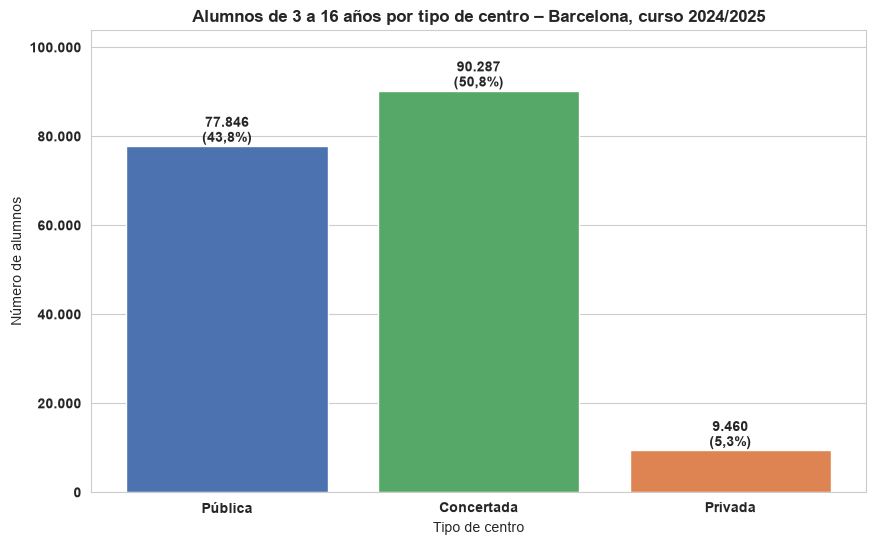

In [33]:
alumnos_por_tipo = df_actual.groupby("tipo_centro")["alumnos_total"].sum().reindex(ORDEN_TIPOS)
porcentaje = alumnos_por_tipo / alumnos_por_tipo.sum() * 100

fig, ax = plt.subplots()
barras = ax.bar(alumnos_por_tipo.index, alumnos_por_tipo.values,
                color=[COLORES_TIPO[t] for t in alumnos_por_tipo.index])
ax.bar_label(barras, labels=[f"{n:,.0f}".replace(",", ".") + f"\n({p:.1f}%)".replace(".", ",") for n, p in zip(alumnos_por_tipo, porcentaje)],
             fontweight="bold")

ax.set_title(f"Alumnos de 3 a 16 años por tipo de centro – Barcelona, curso {CURSO_ACTUAL}")
ax.set_xlabel("Tipo de centro")
ax.set_ylabel("Número de alumnos")
ax.margins(y=0.15)
formatear_ejes(ax)
plt.show()

> **💡 ¿Qué aprendemos?**
> - En el curso 2024/2025 hay **177.593 alumnos** de 3 a 16 años en los centros de Barcelona.
> - La **concertada** es el tipo de centro con más alumnos: **la mitad (50,8%)**.
> - La pública escolariza al **43,8%** y la privada sin concierto solo al **5,3%**.
> - Las proporciones son casi iguales a las de los cinco cursos juntos (51% / 44% / 5%), así que no es una situación puntual de un año, sino una **estructura estable**.

> - **En resumen:** en Barcelona, uno de cada dos niños estudia en una escuela concertada; la escuela privada pura es minoritaria.

### 4.2 Etapa educativa
**❓ ¿Cuántos alumnos hay en cada etapa?**

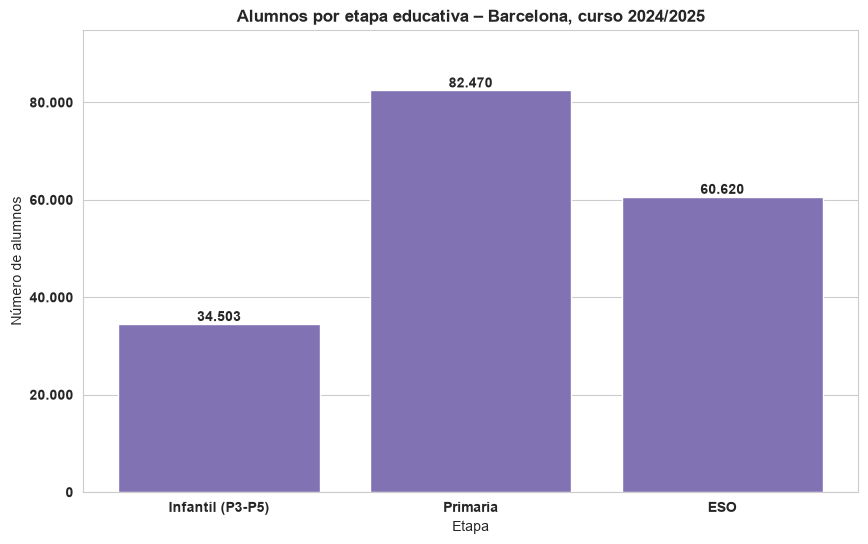

In [34]:
alumnos_por_etapa = df_actual.groupby("etapa")["alumnos_total"].sum().reindex(ORDEN_ETAPAS)

fig, ax = plt.subplots()
barras = ax.bar(alumnos_por_etapa.index, alumnos_por_etapa.values, color="#8172B3")
ax.bar_label(barras, labels=[f"{n:,.0f}".replace(",", ".") for n in alumnos_por_etapa],
             fontweight="bold")

ax.set_title(f"Alumnos por etapa educativa – Barcelona, curso {CURSO_ACTUAL}")
ax.set_xlabel("Etapa")
ax.set_ylabel("Número de alumnos")
ax.margins(y=0.15)
formatear_ejes(ax)
plt.show()

> **💡 ¿Qué aprendemos?**
> - En el curso 2024/2025, **Primaria** es la etapa con más alumnos (**82.470**), seguida de **ESO** (**60.620**) e **Infantil P3-P5** (**34.503**).
> - Pero estas cifras dependen sobre todo del **número de niveles** de cada etapa: Primaria tiene 6 cursos, ESO 4 e Infantil 3. Por eso no podemos comparar los totales directamente.
> - Para una comparación justa, en el siguiente apartado calculamos los **alumnos por nivel**.

> - **En resumen:** Primaria es la etapa más grande porque es la más larga; para comparar etapas hay que mirar los alumnos por curso.

### 4.3 Alumnos por nivel en cada etapa
Las etapas tienen distinto número de niveles (Infantil 3, Primaria 6, ESO 4), así que comparar los totales no es justo. Dividimos por el número de niveles para comparar **cuántos alumnos hay en cada curso de edad**.

**❓ ¿Hay el mismo número de alumnos en cada edad?**

In [35]:
NIVELES_POR_ETAPA = {"Infantil (P3-P5)": 3, "Primaria": 6, "ESO": 4}

por_nivel = alumnos_por_etapa.to_frame("alumnos")
por_nivel["niveles"] = por_nivel.index.map(NIVELES_POR_ETAPA)
por_nivel["alumnos_por_nivel"] = (por_nivel["alumnos"] / por_nivel["niveles"]).round().astype(int)
por_nivel

,alumnos,niveles,alumnos_por_nivel
etapa,,,
Infantil (P3-P5),34503,3,11501
Primaria,82470,6,13745
ESO,60620,4,15155


> **💡 ¿Qué aprendemos?**
> - En ESO hay unos **15.200 alumnos por curso de edad**, en Primaria unos **13.700** y en Infantil unos **11.500**: cuanto más pequeños, menos alumnos.
> - Una posible explicación es la **caída de la natalidad**. Pero hay otras: familias que llegan a Barcelona con hijos mayores, o familias que se van de la ciudad cuando tienen hijos pequeños.
> - Para comprobarlo, en el análisis de tendencias veremos si **P3** baja de un curso a otro.

> - **En resumen:** hoy hay menos niños pequeños que adolescentes en las escuelas de Barcelona; la pregunta es si es por la natalidad.

### 4.4 Alumnos por grupo
**❓ ¿Cuántos alumnos hay normalmente en un grupo (clase)?**

Como decidimos en la limpieza (3.8), calculamos los alumnos por grupo **por centro + etapa + curso**, sumando alumnos y grupos de todos los niveles. Así los grupos mixtos se cuentan bien. Excluimos los centros de sistema extranjero y las combinaciones sin grupos.

In [36]:
df_grupos = (
    df_limpio[~df_limpio["sistema_extranjero"]]
    .groupby(["curso", "codigo_centro", "etapa", "tipo_centro", "distrito"], as_index=False)[["alumnos_total", "grupos"]]
    .sum()
)
df_grupos = df_grupos[df_grupos["grupos"] > 0].copy()
df_grupos["alumnos_por_grupo"] = df_grupos["alumnos_total"] / df_grupos["grupos"]

grupos_actual = df_grupos[df_grupos["curso"] == CURSO_ACTUAL]
print(f"Combinaciones centro-etapa en {CURSO_ACTUAL}: {len(grupos_actual)}")
grupos_actual["alumnos_por_grupo"].describe().round(1)

Combinaciones centro-etapa en 2024/2025: 891


count    891.0
mean      22.9
std        5.0
min        3.0
25%       20.0
50%       22.8
75%       25.8
max       33.1
Name: alumnos_por_grupo, dtype: Float64

In [37]:
grupos_actual.groupby("etapa")["alumnos_por_grupo"].median().round(1).reindex(ORDEN_ETAPAS)

etapa
Infantil (P3-P5)    20.0
Primaria            23.6
ESO                 29.5
Name: alumnos_por_grupo, dtype: Float64

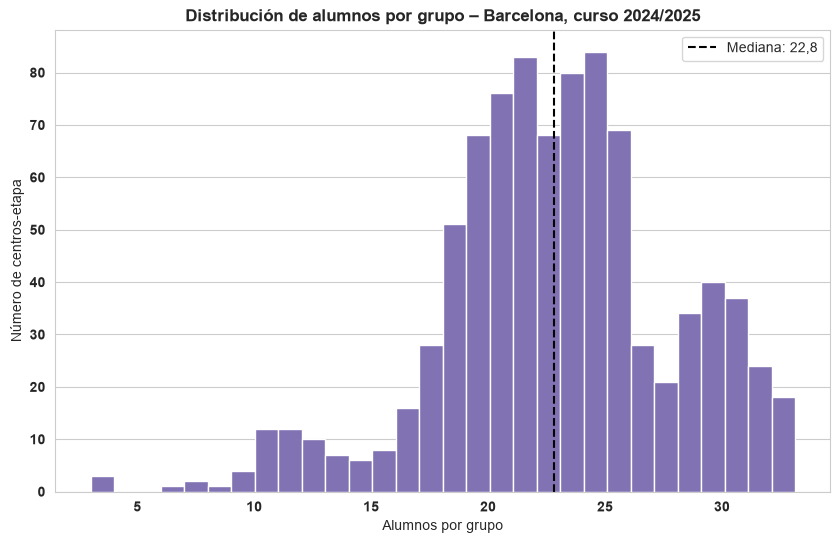

In [38]:
fig, ax = plt.subplots()
ax.hist(grupos_actual["alumnos_por_grupo"], bins=30, color="#8172B3", edgecolor="white")

mediana = grupos_actual["alumnos_por_grupo"].median()
ax.axvline(mediana, color="black", linestyle="--", linewidth=1.5, label=f"Mediana: {mediana:.1f}".replace(".", ","))

ax.set_title(f"Distribución de alumnos por grupo – Barcelona, curso {CURSO_ACTUAL}")
ax.set_xlabel("Alumnos por grupo")
ax.set_ylabel("Número de centros-etapa")
ax.legend()
formatear_ejes(ax)
plt.show()

> **💡 ¿Qué aprendemos?**
> - La mediana es de **22,8 alumnos por grupo**, pero la distribución tiene **dos picos**: uno alrededor de 20-25 y otro alrededor de 30.
> - Los picos corresponden a las etapas: la mediana es de **20,0 en Infantil**, **23,6 en Primaria** y **29,5 en ESO**. En ESO los grupos están casi en el **máximo legal** (30 alumnos; 25 en Primaria, LOE art. 157).
> - A la izquierda hay grupos pequeños (menos de 15 alumnos): sobre todo **escuelas públicas pequeñas** de Infantil y Primaria y **centros privados**.

> - **En resumen:** el tamaño de la clase depende sobre todo de la etapa; en la ESO las aulas están prácticamente llenas.

### 4.5 Valores atípicos (outliers) en alumnos por grupo
**❓ ¿Hay grupos anormalmente pequeños o grandes?**

Usamos el **rango intercuartílico (IQR)**: un valor es atípico si está por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR. Lo calculamos **por etapa**, porque el tamaño normal de un grupo es distinto en Infantil, Primaria y ESO.


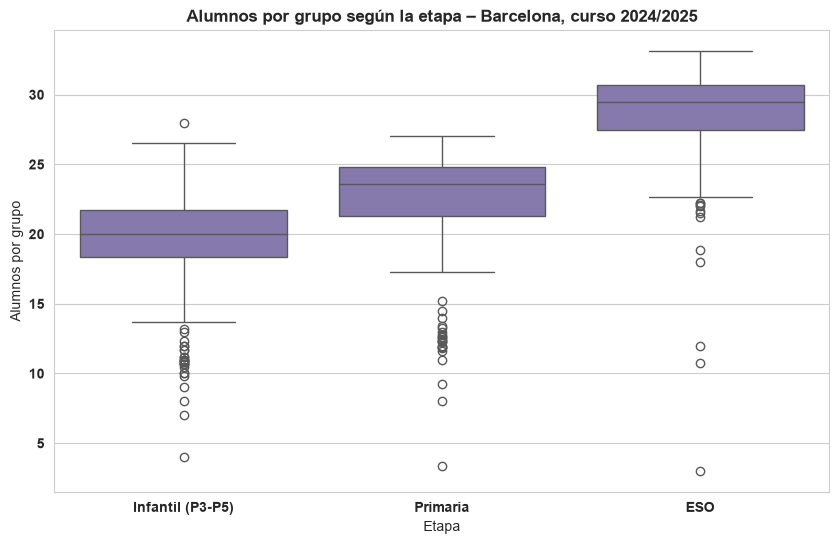

In [39]:
fig, ax = plt.subplots()
sns.boxplot(data=grupos_actual, x="etapa", y="alumnos_por_grupo", order=ORDEN_ETAPAS, color="#8172B3", ax=ax)

ax.set_title(f"Alumnos por grupo según la etapa – Barcelona, curso {CURSO_ACTUAL}")
ax.set_xlabel("Etapa")
ax.set_ylabel("Alumnos por grupo")
formatear_ejes(ax)
plt.show()

In [40]:
def limites_iqr(serie):
    """Devuelve los límites inferior y superior para detectar outliers con el método IQR."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


resumen = []
for etapa in ORDEN_ETAPAS:
    valores = grupos_actual.loc[grupos_actual["etapa"] == etapa, "alumnos_por_grupo"]
    inferior, superior = limites_iqr(valores)
    resumen.append({
        "etapa": etapa,
        "limite_inferior": round(inferior, 1),
        "limite_superior": round(superior, 1),
        "outliers_bajos": (valores < inferior).sum(),
        "outliers_altos": (valores > superior).sum(),
    })

pd.DataFrame(resumen)

,etapa,limite_inferior,limite_superior,outliers_bajos,outliers_altos
0,Infantil (P3-P5),13.2,26.8,26,1
1,Primaria,16.0,30.1,22,0
2,ESO,22.6,35.6,12,0


> **💡 ¿Qué aprendemos?**
> - Hay **61 combinaciones centro-etapa atípicas** en 2024/2025: **60 son grupos pequeños** y solo 1 es un grupo grande.
> - Son sobre todo **centros muy pequeños**, públicos (32) y privados (26). Casi ninguno es concertado (3): los centros concertados deben mantener una ratio mínima de alumnos por unidad.
> - Algunos casos privados vienen de centros con concierto distinto según el nivel (ver 3.11), donde la parte no concertada tiene pocos alumnos.

> **✅ Decisión:** **no eliminamos** los outliers: son centros reales, no errores. Para comparar grupos usaremos la **mediana**, que es más robusta frente a valores extremos que la media.

> 📋 *Para el informe de calidad de datos:* 61 outliers por IQR en alumnos por grupo (60 bajos) → mantenidos; son centros pequeños reales.

## 🔗 Paso 5: Análisis bivariado
Analizamos la **relación entre dos variables**.

### 5.1 Tipo de centro según el distrito
**❓ ¿Hay distritos donde predomina la escuela concertada o privada?**

Los distritos tienen tamaños muy distintos, así que comparamos **porcentajes** (qué parte de los alumnos de cada distrito va a cada tipo de centro), no totales.

In [41]:
tipo_por_distrito = pd.crosstab(
    df_actual["distrito"],
    df_actual["tipo_centro"],
    values=df_actual["alumnos_total"],
    aggfunc="sum",
    normalize="index",
)[ORDEN_TIPOS] * 100

tipo_por_distrito = tipo_por_distrito.sort_values("Pública")
tipo_por_distrito.round(1)

tipo_centro,Pública,Concertada,Privada
distrito,,,
Sarrià - Sant Gervasi,11.5,71.1,17.4
Les Corts,28.6,57.2,14.2
Horta - Guinardó,40.5,57.8,1.7
Eixample,41.0,53.2,5.8
Gràcia,45.5,52.1,2.5
Sant Andreu,55.4,44.4,0.2
Nou Barris,58.3,41.6,0.1
Sants - Montjuïc,59.5,40.5,0.0
Sant Martí,64.5,35.2,0.2


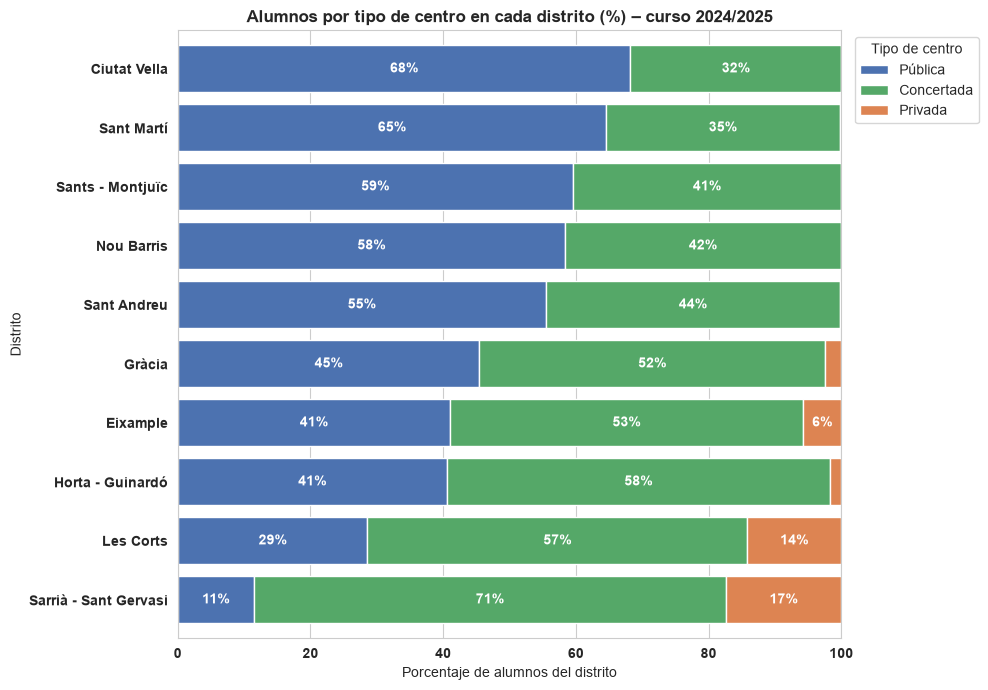

In [42]:
fig, ax = plt.subplots(figsize=(10, 7))
tipo_por_distrito.plot(kind="barh", stacked=True, color=[COLORES_TIPO[t] for t in ORDEN_TIPOS], ax=ax, width=0.8)

for contenedor in ax.containers:
    ax.bar_label(contenedor, labels=[f"{v:.0f}%" if v >= 5 else "" for v in contenedor.datavalues],
                 label_type="center", color="white", fontweight="bold")

ax.set_title(f"Alumnos por tipo de centro en cada distrito (%) – curso {CURSO_ACTUAL}")
ax.set_xlabel("Porcentaje de alumnos del distrito")
ax.set_ylabel("Distrito")
ax.set_xlim(0, 100)
ax.legend(title="Tipo de centro", bbox_to_anchor=(1.01, 1), loc="upper left")
for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
    etiqueta.set_fontweight("bold")
plt.tight_layout()
plt.show()

> **💡 ¿Qué aprendemos?**
> - Las diferencias entre distritos son **enormes**. En **Sarrià - Sant Gervasi** solo el **11,5%** de los alumnos va a la escuela pública; en **Ciutat Vella**, el **68,2%**.
> - La **privada sin concierto** casi solo existe en **Sarrià - Sant Gervasi (17,4%)** y **Les Corts (14,2%)**; en el resto de distritos está por debajo del 6%.
> - La **concertada** es mayoritaria en 5 de los 10 distritos.
> - **Sorpresa:** Horta - Guinardó tiene un 57,8% de concertada, más que Eixample o Gràcia. La concertada no parece depender solo del nivel económico del distrito.
> - **Hipótesis:** los distritos con menos escuela pública (Sarrià - Sant Gervasi, Les Corts) suelen asociarse a rentas altas. Lo comprobaremos con los datos de renta (pregunta 2).

> - **En resumen:** dónde vives cambia mucho a qué tipo de escuela van los niños: en Sarrià - Sant Gervasi solo **1 de cada 10** va a la escuela pública; en Ciutat Vella, **7 de cada 10**.

### 5.2 Alumnos por grupo según el tipo de centro
**❓ ¿Las clases son más grandes en la pública, en la concertada o en la privada?**

Como el tamaño de los grupos depende mucho de la etapa (4.4), comparamos los tipos de centro **dentro de cada etapa**. Usamos la **mediana** porque hay outliers (4.5).

In [43]:
mediana_grupo = pd.pivot_table(
    grupos_actual,
    values="alumnos_por_grupo",
    index="etapa",
    columns="tipo_centro",
    aggfunc="median",
).reindex(index=ORDEN_ETAPAS, columns=ORDEN_TIPOS).round(1)

mediana_grupo

tipo_centro,Pública,Concertada,Privada
etapa,,,
Infantil (P3-P5),20.0,20.3,12.0
Primaria,23.6,23.9,13.5
ESO,28.4,30.0,21.6


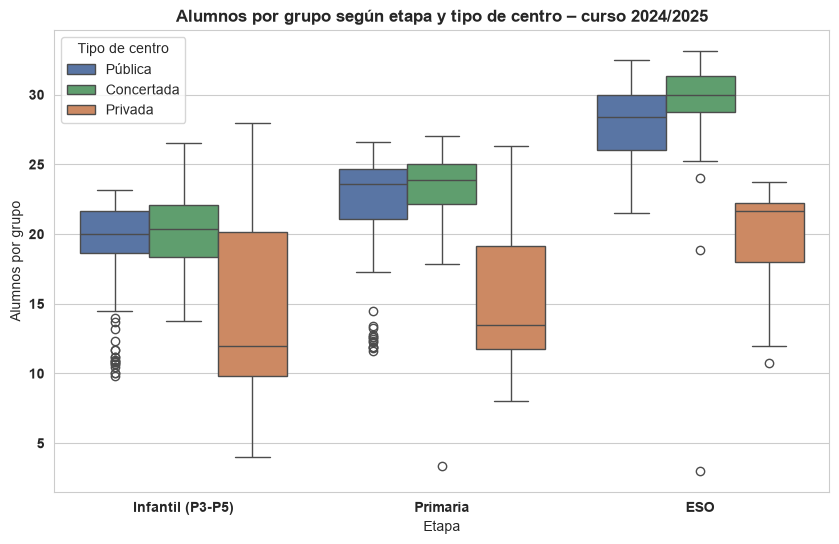

In [44]:
fig, ax = plt.subplots()
sns.boxplot(data=grupos_actual, x="etapa", y="alumnos_por_grupo", hue="tipo_centro",
            order=ORDEN_ETAPAS, hue_order=ORDEN_TIPOS, palette=COLORES_TIPO, ax=ax)

ax.set_title(f"Alumnos por grupo según etapa y tipo de centro – curso {CURSO_ACTUAL}")
ax.set_xlabel("Etapa")
ax.set_ylabel("Alumnos por grupo")
ax.legend(title="Tipo de centro")
formatear_ejes(ax)
plt.show()

> **💡 ¿Qué aprendemos?**
> - En la **privada** los grupos son mucho más pequeños: unos **12-13 alumnos** en Infantil y Primaria, casi la mitad que en la pública.
> - **Sorpresa:** la **concertada no tiene grupos más pequeños que la pública**. En todas las etapas su mediana es igual o un poco mayor, y en **ESO llega a 30 alumnos**, el máximo legal.
> - Ojo: hay pocos centros privados (entre 9 y 15 por etapa), así que sus resultados son menos robustos.

> - **En resumen:** si una familia elige la concertada esperando clases más pequeñas, los datos dicen que no lo son; solo la privada tiene grupos claramente más reducidos.

### 5.3 ¿Quién es el titular de los centros concertados y privados?
**❓ ¿Quiénes son los titulares de los centros concertados (órdenes religiosas, fundaciones, cooperativas...)?**

Comparamos el porcentaje de alumnos según el titular del centro en la concertada y en la privada. En la pública no hace falta: el titular siempre es la Administración (Generalitat 95%, Ayuntamiento 5%).

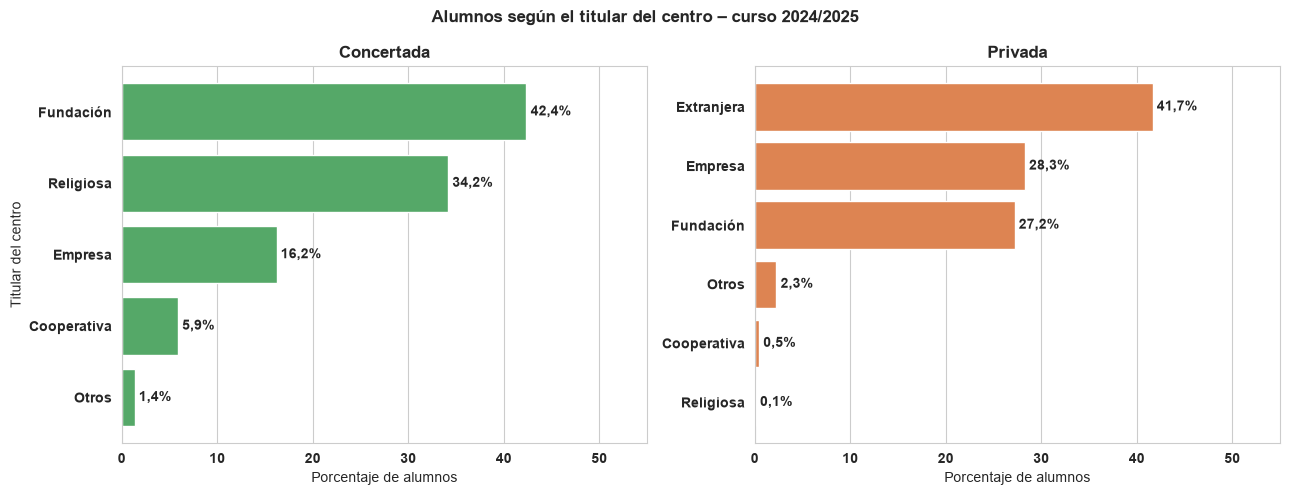

In [45]:
titulares = (
    df_actual[df_actual["tipo_centro"].isin(["Concertada", "Privada"])]
    .groupby(["tipo_centro", "titularidad_grupo"])["alumnos_total"]
    .sum()
)
titulares_pct = titulares / titulares.groupby(level="tipo_centro").transform("sum") * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ax, tipo in zip(axes, ["Concertada", "Privada"]):
    datos = titulares_pct[tipo].sort_values()
    barras = ax.barh(datos.index, datos.values, color=COLORES_TIPO[tipo])
    ax.bar_label(barras, labels=[f"{v:.1f}%".replace(".", ",") for v in datos], padding=3, fontweight="bold")
    ax.set_title(tipo)
    ax.set_xlabel("Porcentaje de alumnos")
    ax.grid(axis="y", visible=False)
    for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
        etiqueta.set_fontweight("bold")
axes[0].set_ylabel("Titular del centro")
axes[0].set_xlim(0, 55)

fig.suptitle(f"Alumnos según el titular del centro – curso {CURSO_ACTUAL}", fontweight="bold")
plt.tight_layout()
plt.show()

In [46]:
PALABRAS_RELIGIOSAS = (
    "Jesuïtes|Maristes|Escolàpies|Escola Pia|Salesià|La Salle|Sagrat Cor|Sagrada Família|"
    "FEDAC|FEP|Vedruna|Dominiques|Teresianes|Cor de Maria|Immaculada|Santa Teresa|Amor de Dios|"
    "Betània|Mare de Déu|Jesús|Maria"
)

concertada = df_actual[df_actual["tipo_centro"] == "Concertada"]
fundaciones = concertada[concertada["titularidad"] == "Fundación"]
fundaciones_religiosas = fundaciones[fundaciones["nombre_centro"].str.contains(PALABRAS_RELIGIOSAS)]

pct_religiosa = (concertada["titularidad_grupo"] == "Religiosa").mul(concertada["alumnos_total"]).sum() / concertada["alumnos_total"].sum() * 100
pct_fund_religiosa = fundaciones_religiosas["alumnos_total"].sum() / concertada["alumnos_total"].sum() * 100

print(f"Titular religioso (dato oficial): {pct_religiosa:.1f}%")
print(f"Fundaciones con nombre religioso (estimación): {pct_fund_religiosa:.1f}%")
print(f"Origen religioso estimado: {pct_religiosa + pct_fund_religiosa:.1f}%")

Titular religioso (dato oficial): 34.2%
Fundaciones con nombre religioso (estimación): 29.9%
Origen religioso estimado: 64.0%


> **💡 ¿Qué aprendemos?**
> - En la **concertada**, el titular más frecuente es una **fundación (42%)**, seguida de las **órdenes e instituciones religiosas (34%)**, las **empresas (16%)** y las **cooperativas (6%)**.
> - Pero muchas órdenes religiosas gestionan sus escuelas a través de fundaciones (por ejemplo, *Fundació Jesuïtes Educació*). Buscando nombres religiosos entre las fundaciones (Jesuïtes, Maristes, Escolàpies, Vedruna, Sagrat Cor, FEDAC...), estimamos que suman un **30% más**. Así, el peso real de la escuela de **origen religioso en la concertada es de alrededor del 64%**: casi **2 de cada 3 alumnos**. Es una **estimación** basada en los nombres de los centros, no un dato oficial: puede incluir algún centro no religioso y dejar fuera otros que sí lo son.

> - **En resumen:** casi 2 de cada 3 alumnos de la concertada estudian en un centro de origen religioso; la privada sin concierto es, en buena parte, internacional.

### 5.4 Chicas y chicos según el tipo de centro
**❓ ¿Hay diferencias en el equilibrio entre chicas y chicos según el tipo de centro?**

Creamos una nueva variable: el **porcentaje de chicas** sobre el total de alumnos. Si hubiera equilibrio perfecto, sería cercano al 50%. *Nota: los datos solo registran el sexo de forma binaria (chicas/chicos).*

In [47]:
incoherentes = df_limpio[df_limpio["chicas"] + df_limpio["chicos"] != df_limpio["alumnos_total"]]
print(f"Filas donde chicas + chicos ≠ alumnos_total: {len(incoherentes)}")

Filas donde chicas + chicos ≠ alumnos_total: 0


> Comprobamos que en todas las filas `chicas + chicos = alumnos_total` (0 filas incoherentes). Por eso basta con mirar el porcentaje de chicas: el de chicos es el resto hasta 100%.

In [48]:
chicas_por_tipo = (
    df_actual.groupby(["etapa", "tipo_centro"])[["chicas", "alumnos_total"]].sum()
    .assign(pct_chicas=lambda t: t["chicas"] / t["alumnos_total"] * 100)["pct_chicas"]
    .unstack()
    .reindex(index=ORDEN_ETAPAS, columns=ORDEN_TIPOS)
    .round(1)
)
chicas_por_tipo

tipo_centro,Pública,Concertada,Privada
etapa,,,
Infantil (P3-P5),48.7,48.8,50.9
Primaria,48.5,49.8,48.9
ESO,48.2,49.3,48.6


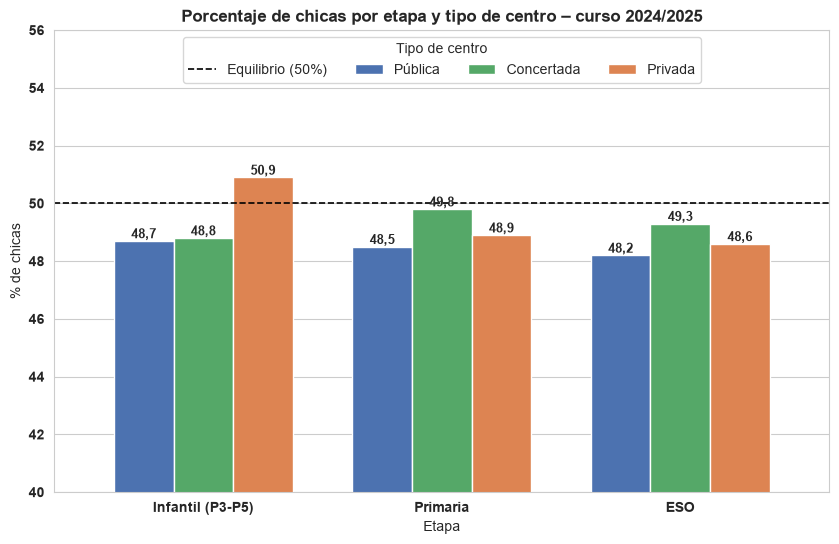

In [49]:
fig, ax = plt.subplots()
chicas_por_tipo.plot(kind="bar", color=[COLORES_TIPO[t] for t in ORDEN_TIPOS], ax=ax, width=0.75)
ax.axhline(50, color="black", linestyle="--", linewidth=1.2, label="Equilibrio (50%)")

for contenedor in ax.containers:
    ax.bar_label(contenedor, labels=[f"{v:.1f}".replace(".", ",") for v in contenedor.datavalues], fontsize=9, fontweight="bold")

ax.set_title(f"Porcentaje de chicas por etapa y tipo de centro – curso {CURSO_ACTUAL}")
ax.set_xlabel("Etapa")
ax.set_ylabel("% de chicas")
ax.set_ylim(40, 56)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Tipo de centro", loc="upper center", ncol=4)
for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
    etiqueta.set_fontweight("bold")
ax.grid(axis="x", visible=False)
plt.show()

> **💡 ¿Qué aprendemos?**
> - El porcentaje de chicas está entre el **48% y el 51%** en todos los tipos de centro y etapas: **no hay diferencias relevantes**.
> - Casi todos los valores están un poco **por debajo del 50%**. Es lo esperado: nacen unos 105 niños por cada 100 niñas, así que la proporción natural de chicas es de alrededor del **48,8%**.
> - La concertada tiene alrededor de **1 punto más de chicas** en Primaria y ESO. Podría ser un rastro de antiguas escuelas solo de chicas, pero la diferencia es muy pequeña.
> - ⚠️ El eje Y empieza en el 40% para que se vean las diferencias; en realidad son **muy pequeñas**.

> - **En resumen:** chicas y chicos se reparten de forma equilibrada entre la pública, la concertada y la privada; el tipo de escuela no depende del sexo.

## 💶 Paso 6: Enriquecer con los datos de renta
Para responder a la pregunta 2 (¿influye la renta del distrito en el tipo de escuela?), añadimos una **segunda fuente de datos**: la *Renda disponible de les llars per persona* del Ajuntament de Barcelona (Open Data BCN).

### 6.1 Cargar los datos de renta desde la API de Open Data BCN
El portal tiene una API (CKAN) que nos da la lista de archivos del dataset. Descargamos los años 2020-2023 (no hay datos de 2024).

In [50]:
URL_CKAN = "https://opendata-ajuntament.barcelona.cat/data/api/3/action/package_show"
ANIOS_RENTA = [2020, 2021, 2022, 2023]

respuesta = requests.get(URL_CKAN, params={"id": "renda-disponible-llars-bcn"})
respuesta.raise_for_status()
recursos = respuesta.json()["result"]["resources"]

urls_renta = {
    int(r["name"][:4]): r["url"]
    for r in recursos
    if r["format"].upper() == "CSV" and int(r["name"][:4]) in ANIOS_RENTA
}

renta = pd.concat([pd.read_csv(url) for url in urls_renta.values()], ignore_index=True)
renta.to_csv("../data/raw/renta_bcn_raw.csv", index=False)

print(f"Años descargados: {sorted(urls_renta)}")
print(f"Filas: {renta.shape[0]}, Columnas: {renta.shape[1]}")
renta.head()

Años descargados: [2020, 2021, 2022, 2023]
Filas: 4272, Columnas: 7


,Any,Codi_Districte,Nom_Districte,Codi_Barri,Nom_Barri,Seccio_Censal,Import_Euros
0,2023,1,Ciutat Vella,1,el Raval,1,17508
1,2023,1,Ciutat Vella,1,el Raval,2,15133
2,2023,1,Ciutat Vella,1,el Raval,3,14713
3,2023,1,Ciutat Vella,1,el Raval,4,17916
4,2023,1,Ciutat Vella,1,el Raval,5,15527


### 6.2 Explorar los datos de renta

In [51]:
renta.info()
print(f"\nDistritos: {sorted(renta['Codi_Districte'].unique())}")
renta.groupby("Any")["Import_Euros"].describe().round(0)

<class 'pandas.DataFrame'>
RangeIndex: 4272 entries, 0 to 4271
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Any             4272 non-null   int64
 1   Codi_Districte  4272 non-null   int64
 2   Nom_Districte   4272 non-null   str  
 3   Codi_Barri      4272 non-null   int64
 4   Nom_Barri       4272 non-null   str  
 5   Seccio_Censal   4272 non-null   int64
 6   Import_Euros    4272 non-null   int64
dtypes: int64(5), str(2)
memory usage: 355.4 KB

Distritos: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


,count,mean,std,min,25%,50%,75%,max
Any,,,,,,,,
2020,1068.0,21076.0,5453.0,8624.0,17555.0,20570.0,23516.0,38823.0
2021,1068.0,22144.0,4785.0,9622.0,18946.0,21984.0,24610.0,37425.0
2022,1068.0,23187.0,5221.0,10298.0,19828.0,22811.0,25754.0,40393.0
2023,1068.0,26319.0,7804.0,11097.0,21347.0,24926.0,28947.0,54089.0


In [52]:
renta_media_anual = renta.groupby("Any")["Import_Euros"].mean()
print("Variación de la renta media de Barcelona (%):")
print(renta_media_anual.pct_change().mul(100).round(1).dropna().to_string())

renta_por_distrito = renta.groupby(["Codi_Districte", "Nom_Districte"])[["Any", "Import_Euros"]].apply(
    lambda t: t.groupby("Any")["Import_Euros"].mean()
)
variacion_2023 = (renta_por_distrito[2023] / renta_por_distrito[2022] - 1).mul(100).round(1)
print("\nVariación 2022 → 2023 por distrito (%):")
variacion_2023.sort_values(ascending=False)

Variación de la renta media de Barcelona (%):
Any
2021     5.1
2022     4.7
2023    13.5

Variación 2022 → 2023 por distrito (%):


Codi_Districte  Nom_Districte     
5               Sarrià-St. Gervasi    29.6
4               Les Corts             18.8
2               Eixample              14.9
6               Gràcia                13.4
1               Ciutat Vella          12.4
10              Sant Martí             9.4
7               Horta-Guinardó         9.2
3               Sants-Montjuïc         8.2
9               Sant Andreu            7.1
8               Nou Barris             6.6
dtype: float64

> **💡 ¿Qué aprendemos?** Los datos están completos (sin nulos) y los 10 distritos aparecen en todos los años. Pero la renta media sube un **+5% al año hasta 2022 y un +13,5% en 2023**; en Sarrià - Sant Gervasi, un **+29,6%**. Puede ser un cambio real o un **cambio de metodología** de la fuente.

> **✅ Decisión:** no comparamos años entre sí, sino **distritos dentro del mismo año**. Aun así, comprobaremos los resultados también con la renta de 2022 para asegurarnos de que el salto de 2023 no cambia las conclusiones.

> 📋 *Para el informe de calidad de datos:* salto anómalo de la renta en 2023 (+13,5% de media, +29,6% en Sarrià - Sant Gervasi) → comprobación de robustez con 2022.